# Practical quantization: FP32 vs INT8 (8-bit), step by step

This notebook demonstrates, end to end, what **8-bit post-training quantization** does to a real model.

The pipeline:

1. Download a **real dataset** from the web (CIFAR-10 -- 32x32 colour photographs of 10 object classes). Nothing is downloaded by hand, and no images are generated or drawn.
2. Train a small **FP32 (32-bit float) CNN** on 50,000 of those images.
3. Feed the **10,000 held-out test images** to the FP32 model and look at the accuracy, the per-class results and individual predictions.
4. Take **that same trained model** and quantize it to **INT8 (8-bit)**:
   - fold BatchNorm into the convolutions,
   - calibrate on a few hundred real images so every activation can record its range,
   - convert weights *and* activations to 8-bit integers.
5. Feed the **same test images** to the INT8 model and look at the results.
6. Compare the two: accuracy, model file size, CPU latency, per-class accuracy, agreement between the models, and what rounding does to the actual weight values.

**Before you run:** `Runtime -> Change runtime type -> T4 GPU` makes training take a few minutes instead of roughly 10-20 minutes on CPU. Everything else is identical. The *quantized* model always runs on the **CPU**, because that is where PyTorch's INT8 kernels live.


In [1]:
import copy
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0 if os.name == "nt" else 2

print("torch      :", torch.__version__)
print("torchvision:", torchvision.__version__)
print("device     :", device)


torch      : 2.11.0+cu130
torchvision: 0.26.0+cu130
device     : cuda


100%|██████████| 170M/170M [29:09<00:00, 97.5kB/s]


training images : 50000
test images     : 10000
epochs          : 8


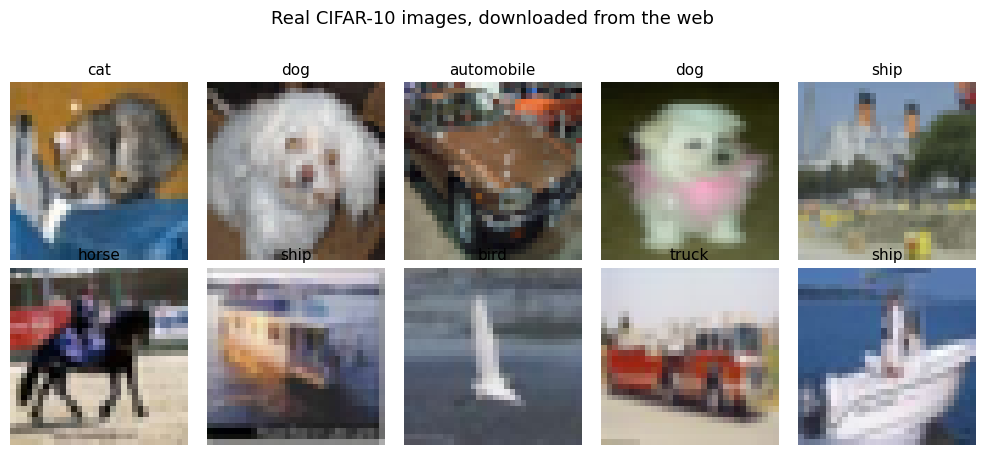

In [2]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

# download=True fetches the dataset straight from the web the first time and caches it
train_set = datasets.CIFAR10(root="./cifar10", train=True, download=True, transform=train_transform)
calib_set = datasets.CIFAR10(root="./cifar10", train=True, download=True, transform=eval_transform)
test_set = datasets.CIFAR10(root="./cifar10", train=False, download=True, transform=eval_transform)
raw_test = datasets.CIFAR10(root="./cifar10", train=False, download=True, transform=transforms.ToTensor())

BATCH_SIZE = 128
TRAIN_N = 50000 if device.type == "cuda" else 12000   # keep CPU runs reasonably quick
EPOCHS = 8 if device.type == "cuda" else 6

train_loader = DataLoader(Subset(train_set, range(TRAIN_N)), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
# representative images used later to calibrate the quantizer
calib_loader = DataLoader(Subset(calib_set, range(512)), batch_size=64, shuffle=False)

print(f"training images : {TRAIN_N}")
print(f"test images     : {len(test_set)}")
print(f"epochs          : {EPOCHS}")

# a quick look at genuine photographic data (one image from each class)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.6))
for ax, i in zip(axes.ravel(), range(10)):
    image, label = raw_test[i * 1000]
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(CLASSES[label], fontsize=11)
    ax.axis("off")
fig.suptitle("Real CIFAR-10 images, downloaded from the web", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


In [3]:
from torch.ao.quantization import QuantStub, DeQuantStub


class SimpleCNN(nn.Module):
    """Small CNN written in a quantization-friendly way.

    QuantStub and DeQuantStub are identity operations while the model is FP32.
    During quantization they become the points where the input and the output are
    converted between float and 8-bit integer.
    """

    def __init__(self, num_classes=10):
        super().__init__()
        self.quant = QuantStub()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.relu3 = nn.ReLU()
        self.conv4 = nn.Conv2d(128, 128, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.relu4 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.relu5 = nn.ReLU()
        self.fc2 = nn.Linear(256, num_classes)
        self.dequant = DeQuantStub()

    def forward(self, x):
        x = self.quant(x)
        x = self.relu1(self.bn1(self.conv1(x)))
        x = self.pool1(self.relu2(self.bn2(self.conv2(x))))
        x = self.relu3(self.bn3(self.conv3(x)))
        x = self.pool2(self.relu4(self.bn4(self.conv4(x))))
        x = torch.flatten(x, 1)
        x = self.relu5(self.fc1(x))
        x = self.fc2(x)
        return self.dequant(x)


model_fp32 = SimpleCNN().to(device)
n_params = sum(p.numel() for p in model_fp32.parameters())

print(f"parameters         : {n_params:,}")
print(f"FP32 weight memory : {n_params * 4 / 1e6:.2f} MB  (4 bytes per parameter)")
print(f"INT8 weight memory : {n_params * 1 / 1e6:.2f} MB  (1 byte per parameter)")
print(model_fp32)


parameters         : 2,341,514
FP32 weight memory : 9.37 MB  (4 bytes per parameter)
INT8 weight memory : 2.34 MB  (1 byte per parameter)
SimpleCNN(
  (quant): QuantStub()
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu1): ReLU()
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu2): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu3): ReLU()
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu4): ReLU()
  

In [4]:
def train(model, loader, epochs, device):
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    for epoch in range(epochs):
        running_loss, correct, seen = 0.0, 0, 0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            seen += labels.size(0)
        scheduler.step()
        print(f"epoch {epoch + 1:2d}/{epochs}   loss {running_loss / seen:.4f}   train accuracy {100 * correct / seen:5.2f}%")
    model.eval()
    return model


print(f"Training the FP32 model on {TRAIN_N} real images for {EPOCHS} epochs...")
model_fp32 = train(model_fp32, train_loader, EPOCHS, device)
print("Training done.")


Training the FP32 model on 50000 real images for 8 epochs...
epoch  1/8   loss 1.5918   train accuracy 42.57%
epoch  2/8   loss 1.1012   train accuracy 60.50%
epoch  3/8   loss 0.9002   train accuracy 67.96%
epoch  4/8   loss 0.7916   train accuracy 71.80%
epoch  5/8   loss 0.7120   train accuracy 75.12%
epoch  6/8   loss 0.6489   train accuracy 77.30%
epoch  7/8   loss 0.5956   train accuracy 79.15%
epoch  8/8   loss 0.5663   train accuracy 80.23%
Training done.


FP32 test accuracy: 80.66%


,FP32 accuracy (%)
class,
airplane,83.8
automobile,89.3
bird,68.6
cat,65.2
deer,80.5
dog,74.3
frog,85.0
horse,81.9
ship,88.1


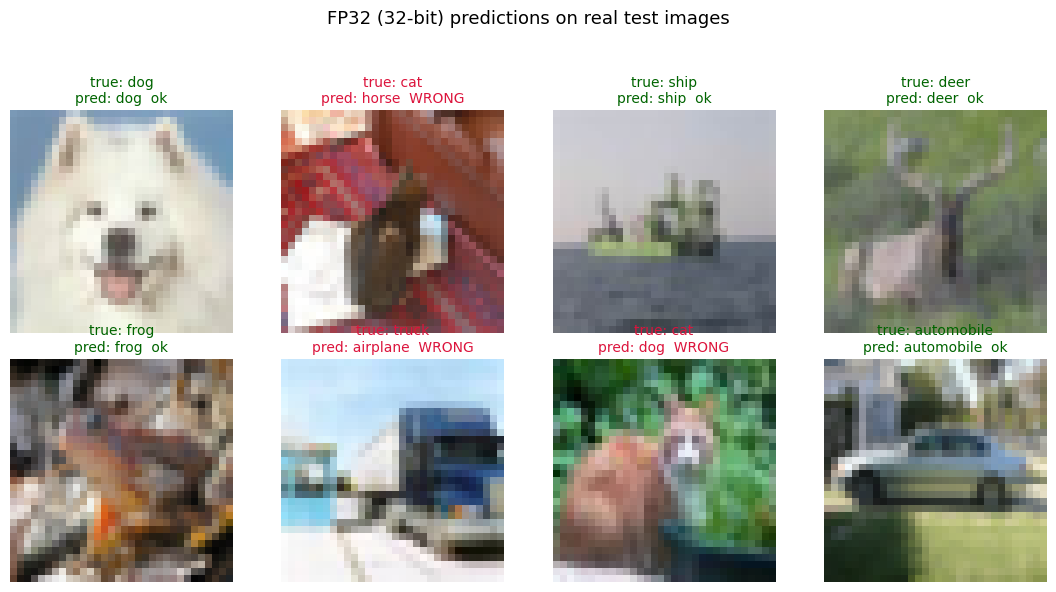

In [5]:
@torch.no_grad()
def evaluate(model, loader, device):
    """Top-1 accuracy, per-class accuracy and the raw predictions (in loader order)."""
    model.eval()
    n = len(loader.dataset)
    predictions = torch.zeros(n, dtype=torch.long)
    targets = torch.zeros(n, dtype=torch.long)
    start = 0
    for images, labels in loader:
        predictions[start:start + len(labels)] = model(images.to(device)).argmax(1).cpu()
        targets[start:start + len(labels)] = labels
        start += len(labels)
    accuracy = (predictions == targets).float().mean().item() * 100
    per_class = []
    for c in range(len(CLASSES)):
        mask = targets == c
        per_class.append(((predictions[mask] == c).float().mean().item() * 100) if mask.any() else float("nan"))
    return accuracy, per_class, predictions, targets


def show_predictions(model, indices, title, device):
    """Feed the chosen test images to a model and draw its predictions."""
    model.eval()
    fig, axes = plt.subplots(2, 4, figsize=(11, 6))
    with torch.no_grad():
        for ax, idx in zip(axes.ravel(), indices):
            image_tensor, label = test_set[idx]
            prediction = model(image_tensor.unsqueeze(0).to(device)).argmax(1).item()
            is_correct = prediction == label
            ax.imshow(raw_test[idx][0].permute(1, 2, 0).numpy(), interpolation="nearest")
            ax.set_title(f"true: {CLASSES[label]}\npred: {CLASSES[prediction]}  {'ok' if is_correct else 'WRONG'}",
                         fontsize=10, color="darkgreen" if is_correct else "crimson")
            ax.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()


# the same 8 images are reused for the quantized model later
SAMPLE_IDX = np.random.RandomState(0).choice(len(test_set), 8, replace=False).tolist()

accuracy_fp32, per_class_fp32, preds_fp32, test_labels = evaluate(model_fp32, test_loader, device)
print(f"FP32 test accuracy: {accuracy_fp32:.2f}%")

display(pd.DataFrame({
    "class": CLASSES,
    "FP32 accuracy (%)": np.round(per_class_fp32, 2),
}).set_index("class"))

show_predictions(model_fp32, SAMPLE_IDX, "FP32 (32-bit) predictions on real test images", device)


In [6]:
from torch.ao.quantization import convert, fuse_modules, get_default_qconfig, prepare

# choose the CPU backend and its default 8-bit quantization settings
try:
    torch.backends.quantized.engine = "x86"
    qconfig = get_default_qconfig("x86")
except Exception:
    torch.backends.quantized.engine = "fbgemm"
    qconfig = get_default_qconfig("fbgemm")
print("quantization backend:", torch.backends.quantized.engine)
print("qconfig             :", qconfig)

# work on a copy so the FP32 model stays untouched
model_to_quantize = copy.deepcopy(model_fp32).cpu().eval()

# step 1 - fuse Conv + BatchNorm + ReLU and Linear + ReLU into single blocks.
# Folding BatchNorm into the convolution is mathematically identical, and it lets
# each convolution become one INT8 kernel.
model_to_quantize = fuse_modules(model_to_quantize, [
    ["conv1", "bn1", "relu1"],
    ["conv2", "bn2", "relu2"],
    ["conv3", "bn3", "relu3"],
    ["conv4", "bn4", "relu4"],
    ["fc1", "relu5"],
])

# step 2 - insert observers; the model still computes in FP32 at this point
model_to_quantize.qconfig = qconfig
prepared_model = prepare(model_to_quantize, inplace=False)

# step 3 - calibration: run a few hundred real training images through the model so
# every activation layer can record the range used to build its scale
prepared_model.eval()
with torch.no_grad():
    for images, _ in calib_loader:
        prepared_model(images)

# step 4 - freeze those ranges and swap every target layer for its INT8 version
model_int8 = convert(prepared_model, inplace=False)

print("\nlayer types after quantization:")
for name in ["quant", "conv1", "conv2", "conv3", "conv4", "fc1", "fc2", "dequant"]:
    print(f"  {name}: {type(getattr(model_int8, name)).__name__}")

# read the weights back out of the quantized convolution and show that they are 8-bit
weight = model_int8.conv1.weight()
codes = weight.int_repr() if weight.dtype == torch.qint8 else weight
values = weight.dequantize() if weight.dtype == torch.qint8 else weight.float()
fp32_weight = model_fp32.conv1.weight.detach().cpu().flatten()

print("\nconv1 weights before and after quantization")
print(f"  FP32  dtype={fp32_weight.dtype}  first values={[round(v, 4) for v in fp32_weight[:5].tolist()]}")
print(f"  INT8  dtype={weight.dtype}  integer codes={codes.flatten()[:8].tolist()}")
print(f"  INT8  distinct levels used: {torch.unique(codes).numel()} of 256 possible (-128..127)")
print(f"  INT8  values after de-quantization: {values.min().item():.4f} .. {values.max().item():.4f}")


quantization backend: x86
qconfig             : QConfig(activation=functools.partial(<class 'torch.ao.quantization.observer.HistogramObserver'>, reduce_range=True){}, weight=functools.partial(<class 'torch.ao.quantization.observer.PerChannelMinMaxObserver'>, dtype=torch.qint8, qscheme=torch.per_channel_symmetric){})


/tmp/ipykernel_2917/3183290425.py:29: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared_model = prepare(model_to_quantize, inplace=False)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future re


layer types after quantization:
  quant: Quantize
  conv1: ConvReLU2d
  conv2: ConvReLU2d
  conv3: ConvReLU2d
  conv4: ConvReLU2d
  fc1: LinearReLU
  fc2: Linear
  dequant: DeQuantize

conv1 weights before and after quantization
  FP32  dtype=torch.float32  first values=[0.0196, 0.1295, -0.0857, 0.085, -0.0318]
  INT8  dtype=torch.qint8  integer codes=[12, 77, -51, 51, -19, 47, -110, 39]
  INT8  distinct levels used: 241 of 256 possible (-128..127)
  INT8  values after de-quantization: -1.1139 .. 1.2220


/tmp/ipykernel_2917/3183290425.py:39: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8 = convert(prepared_model, inplace=False)


INT8 test accuracy: 80.61%   (change vs FP32: -0.05 percentage points)


,FP32 accuracy (%),INT8 accuracy (%)
class,,
airplane,83.8,84.7
automobile,89.3,89.6
bird,68.6,69.1
cat,65.2,67.3
deer,80.5,80.1
dog,74.3,71.8
frog,85.0,84.8
horse,81.9,80.9
ship,88.1,88.3


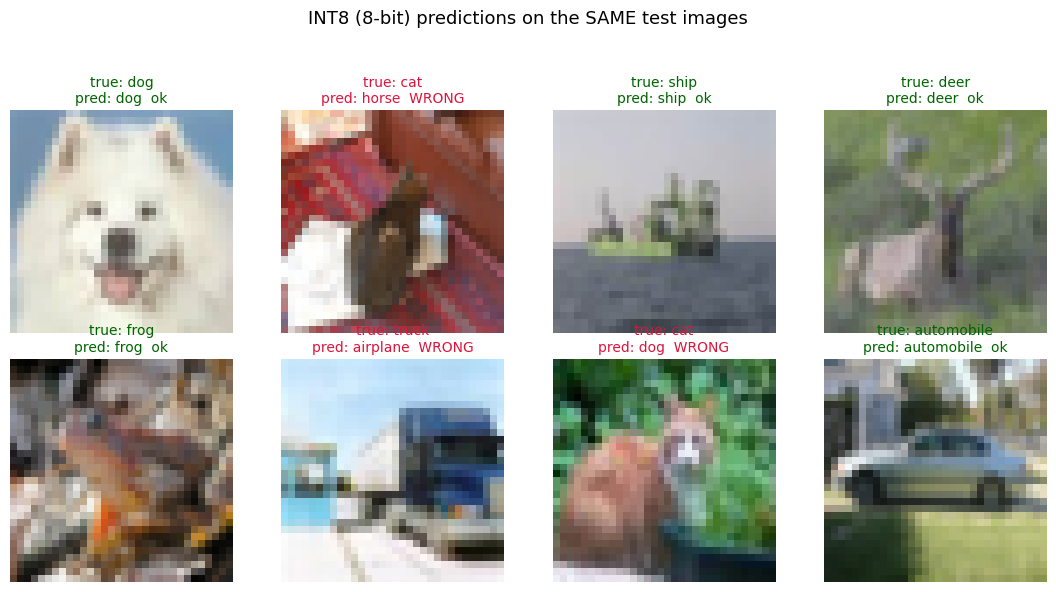

the two models agree on 98.20% of the 10,000 test images
correct -> wrong after quantization : 70 images
wrong   -> correct after quantization : 65 images


In [7]:
accuracy_int8, per_class_int8, preds_int8, labels_int8 = evaluate(model_int8, test_loader, "cpu")

assert torch.equal(labels_int8, test_labels), "evaluation order changed, the comparison would be invalid"

print(f"INT8 test accuracy: {accuracy_int8:.2f}%   (change vs FP32: {accuracy_int8 - accuracy_fp32:+.2f} percentage points)")

display(pd.DataFrame({
    "class": CLASSES,
    "FP32 accuracy (%)": np.round(per_class_fp32, 2),
    "INT8 accuracy (%)": np.round(per_class_int8, 2),
}).set_index("class"))

show_predictions(model_int8, SAMPLE_IDX, "INT8 (8-bit) predictions on the SAME test images", "cpu")

fp32_right = preds_fp32 == test_labels
int8_right = preds_int8 == test_labels
agreement = (preds_fp32 == preds_int8).float().mean().item() * 100
print(f"the two models agree on {agreement:.2f}% of the {len(test_labels):,} test images")
print(f"correct -> wrong after quantization : {(fp32_right & ~int8_right).sum().item()} images")
print(f"wrong   -> correct after quantization : {(~fp32_right & int8_right).sum().item()} images")


In [8]:
def latency_ms(model, batch, runs=30, warmup=5):
    model.eval()
    with torch.no_grad():
        for _ in range(warmup):
            model(batch)
        start = time.perf_counter()
        for _ in range(runs):
            model(batch)
    return (time.perf_counter() - start) / runs * 1000


# PyTorch's INT8 kernels run on the CPU, so both models are timed on the CPU
fp32_on_cpu = copy.deepcopy(model_fp32).cpu().eval()
benchmark_batch = torch.stack([test_set[i][0] for i in range(BATCH_SIZE)])

latency_fp32 = latency_ms(fp32_on_cpu, benchmark_batch)
latency_int8 = latency_ms(model_int8, benchmark_batch)

torch.save(model_fp32.state_dict(), "fp32_model.pt")
try:
    torch.save(model_int8.state_dict(), "int8_model.pt")
except Exception as error:
    print("state_dict save failed, saving the module itself instead:", error)
    torch.save(model_int8, "int8_model.pt")
size_fp32 = os.path.getsize("fp32_model.pt") / 1e6
size_int8 = os.path.getsize("int8_model.pt") / 1e6

comparison = pd.DataFrame({
    "FP32 (32-bit)": [f"{accuracy_fp32:.2f}", f"{size_fp32:.2f}", f"{latency_fp32:.2f}", "float32"],
    "INT8 (8-bit)": [f"{accuracy_int8:.2f}", f"{size_int8:.2f}", f"{latency_int8:.2f}", "int8"],
}, index=["test accuracy (%)", "model file size (MB)", f"CPU latency (ms / batch of {BATCH_SIZE})", "weight dtype"])
display(comparison)

print(f"accuracy change : {accuracy_int8 - accuracy_fp32:+.2f} percentage points")
print(f"model size      : {size_fp32:.2f} MB -> {size_int8:.2f} MB  ({size_fp32 / size_int8:.2f}x smaller, 4x is the theoretical limit)")
print(f"CPU latency     : {latency_fp32:.2f} ms -> {latency_int8:.2f} ms  ({latency_fp32 / latency_int8:.2f}x faster)")


,FP32 (32-bit),INT8 (8-bit)
test accuracy (%),80.66,80.61
model file size (MB),9.38,2.36
CPU latency (ms / batch of 128),351.77,178.30
weight dtype,float32,int8


accuracy change : -0.05 percentage points
model size      : 9.38 MB -> 2.36 MB  (3.97x smaller, 4x is the theoretical limit)
CPU latency     : 351.77 ms -> 178.30 ms  (1.97x faster)


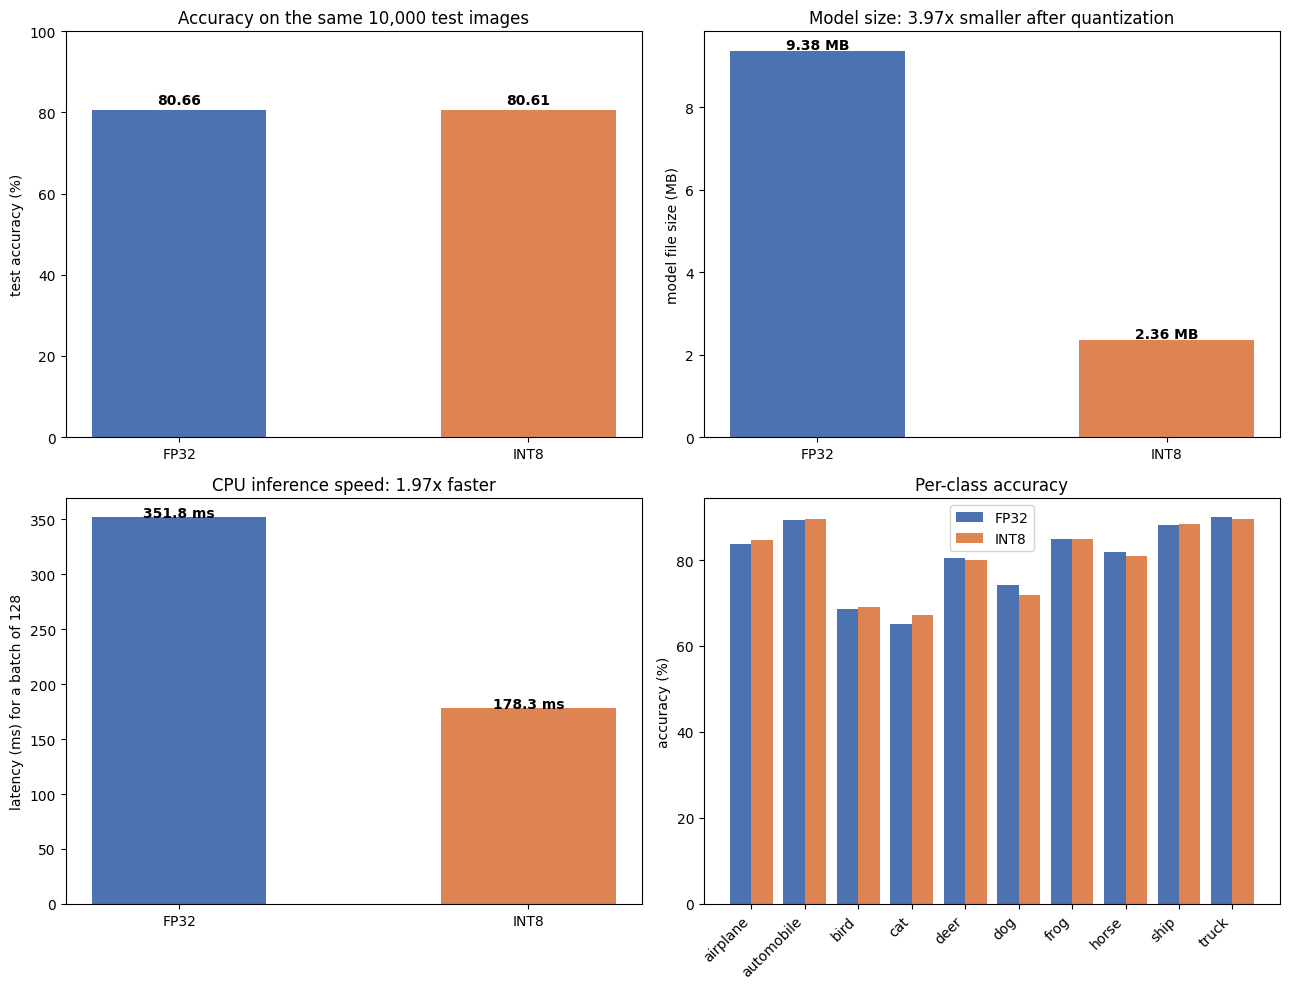

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# accuracy
ax = axes[0, 0]
values = [accuracy_fp32, accuracy_int8]
bars = ax.bar(["FP32", "INT8"], values, color=["#4C72B0", "#DD8452"], width=0.5)
ax.set_ylim(0, 100)
ax.set_ylabel("test accuracy (%)")
ax.set_title(f"Accuracy on the same {len(test_set):,} test images")
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1.5, f"{value:.2f}", ha="center", fontweight="bold")

# model size
ax = axes[0, 1]
values = [size_fp32, size_int8]
bars = ax.bar(["FP32", "INT8"], values, color=["#4C72B0", "#DD8452"], width=0.5)
ax.set_ylabel("model file size (MB)")
ax.set_title(f"Model size: {size_fp32 / size_int8:.2f}x smaller after quantization")
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.03, f"{value:.2f} MB", ha="center", fontweight="bold")

# inference latency
ax = axes[1, 0]
values = [latency_fp32, latency_int8]
bars = ax.bar(["FP32", "INT8"], values, color=["#4C72B0", "#DD8452"], width=0.5)
ax.set_ylabel(f"latency (ms) for a batch of {BATCH_SIZE}")
ax.set_title(f"CPU inference speed: {latency_fp32 / latency_int8:.2f}x faster")
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.4, f"{value:.1f} ms", ha="center", fontweight="bold")

# per-class accuracy
ax = axes[1, 1]
positions = np.arange(len(CLASSES))
ax.bar(positions - 0.2, per_class_fp32, 0.4, label="FP32", color="#4C72B0")
ax.bar(positions + 0.2, per_class_int8, 0.4, label="INT8", color="#DD8452")
ax.set_xticks(positions)
ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_ylabel("accuracy (%)")
ax.set_title("Per-class accuracy")
ax.legend()

fig.tight_layout()
plt.show()


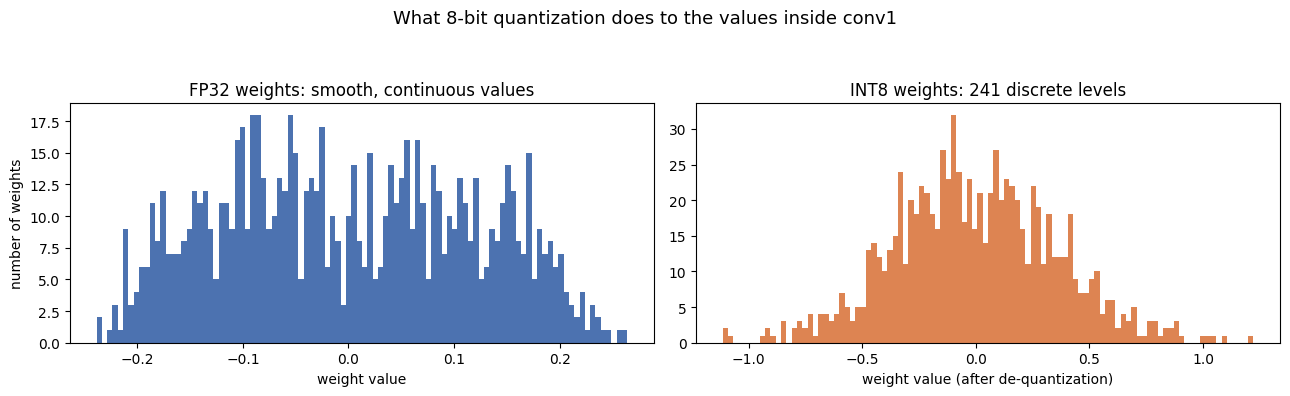

FP32 weight range      : -0.2386 .. 0.2642
INT8 integer codes used: 241 out of 256 possible


In [10]:
fp32_weights = model_fp32.conv1.weight.detach().cpu().flatten().numpy()

int8_weight_tensor = model_int8.conv1.weight()
if int8_weight_tensor.dtype == torch.qint8:
    int8_codes = int8_weight_tensor.int_repr()
    int8_weights = int8_weight_tensor.dequantize().cpu().flatten().numpy()
else:
    int8_codes = int8_weight_tensor
    int8_weights = int8_weight_tensor.float().cpu().flatten().numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(fp32_weights, bins=100, color="#4C72B0")
axes[0].set_title("FP32 weights: smooth, continuous values")
axes[0].set_xlabel("weight value")
axes[0].set_ylabel("number of weights")
axes[1].hist(int8_weights, bins=100, color="#DD8452")
axes[1].set_title(f"INT8 weights: {torch.unique(int8_codes).numel()} discrete levels")
axes[1].set_xlabel("weight value (after de-quantization)")
fig.suptitle("What 8-bit quantization does to the values inside conv1", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

print(f"FP32 weight range      : {fp32_weights.min():.4f} .. {fp32_weights.max():.4f}")
print(f"INT8 integer codes used: {torch.unique(int8_codes).numel()} out of 256 possible")


## Comparison 2: the same trained model at 4 bits

8-bit barely touched the model, so now we push the *same trained weights* down to **4 bits**. This is the standard "int4 weight-only" setting used in practice (it is what torchao's `int4_weight_only` does):

- **Weights:** 4 bits, per output channel, symmetric. Each channel gets its own step: `scale = max|w| / 7`, and every weight is rounded to a code in `-8 ... 7` -- 16 levels instead of 256.
- **Activations:** left in float. 4-bit activations are not standard practice; they break most networks, so real int4 quantizes weights only.
- **Storage:** the codes are packed **two per byte**, so the size below is a real 4-bit size, not a simulation.

The rounding error per weight is now `scale / 2 = max|w| / 14`, roughly **18x larger** than in the 8-bit model. That is where the accuracy difference should finally appear.

Two things to know before reading the numbers:

- PyTorch has **no 4-bit CPU kernel**, so the model unpacks the weights and computes in float. Accuracy and size below are real; the latency row is **not** a speed claim.
- It is still the same trained weights, with no retraining -- exactly like the 8-bit case.


In [ ]:
# ---- Build a real 4-bit (int4 weight-only) copy of the same trained model ----
def int4_codes_and_scales(weight):
    """Per output-channel symmetric 4-bit codes: scale = max|w| / 7, codes in -8..7."""
    flat = weight.reshape(weight.shape[0], -1)
    scale = (flat.abs().amax(dim=1, keepdim=True) / 7.0).clamp_min(1e-12)
    codes = torch.clamp(torch.round(flat / scale), -8, 7).to(torch.int16)
    return codes, scale


def pack_int4(codes):
    """Store two 4-bit codes in one byte (pads a zero code if the row length is odd)."""
    if codes.shape[1] % 2 == 1:
        codes = torch.nn.functional.pad(codes, (0, 1))
    unsigned = (codes + 8).to(torch.int16)                     # -8..7 becomes 0..15
    return (unsigned[:, 0::2] | (unsigned[:, 1::2] << 4)).to(torch.uint8)


# fuse Conv+BN+ReLU first, so we round exactly the weights the model actually uses
model_int4 = fuse_modules(copy.deepcopy(model_fp32).cpu().eval(),
                          [["conv1", "bn1", "relu1"], ["conv2", "bn2", "relu2"],
                           ["conv3", "bn3", "relu3"], ["conv4", "bn4", "relu4"], ["fc1", "relu5"]])

packed_state = {}
for name, module in model_int4.named_modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        codes, scale = int4_codes_and_scales(module.weight.data)
        module.weight.data = (codes.to(scale.dtype) * scale).reshape(module.weight.shape)
        packed_state[name + ".weight_packed"] = pack_int4(codes)
        packed_state[name + ".scales"] = scale.to(torch.float16)
        if module.bias is not None:
            packed_state[name + ".bias"] = module.bias.detach().clone()

torch.save(packed_state, "int4_model.pt")
size_int4 = os.path.getsize("int4_model.pt") / 1e6

print("layers quantized to 4 bits:")
for key in sorted(packed_state):
    if key.endswith("weight_packed"):
        print(f"  {key[:-14]:10s} {packed_state[key].numel():>10,} packed bytes")
print()
print(f"INT4 model file : {size_int4:.2f} MB   "
      f"({size_fp32 / size_int4:.2f}x smaller than FP32, {size_int8 / size_int4:.2f}x smaller than INT8)")

conv1_module = next(m for m in model_int4.conv1.modules() if isinstance(m, nn.Conv2d))
codes1, _ = int4_codes_and_scales(conv1_module.weight.data)
print(f"distinct 4-bit levels used in conv1 : {torch.unique(codes1).numel()} of 16 possible (-8..7)")
print(f"conv1 weight values after rounding  : {[round(v, 5) for v in conv1_module.weight.detach().flatten()[:6].tolist()]}")


In [ ]:
# ---- Evaluate the 4-bit model on the SAME test images ----
accuracy_int4, per_class_int4, preds_int4, labels_int4 = evaluate(model_int4, test_loader, "cpu")
assert torch.equal(labels_int4, test_labels)

print(f"INT4 test accuracy: {accuracy_int4:.2f}%   (change vs FP32: {accuracy_int4 - accuracy_fp32:+.2f} percentage points)")

display(pd.DataFrame({
    "class": CLASSES,
    "FP32 accuracy (%)": np.round(per_class_fp32, 2),
    "INT4 accuracy (%)": np.round(per_class_int4, 2),
    "difference (pp)": np.round(np.array(per_class_int4) - np.array(per_class_fp32), 2),
}).set_index("class"))

show_predictions(model_int4, SAMPLE_IDX, "INT4 (4-bit weights) predictions on the SAME test images", "cpu")

int4_right = preds_int4 == test_labels
print(f"agreement with FP32 : {(preds_fp32 == preds_int4).float().mean().item() * 100:.2f}% of the 10,000 test images")
print(f"correct -> wrong : {(fp32_right & ~int4_right).sum().item()} images")
print(f"wrong   -> correct : {(~fp32_right & int4_right).sum().item()} images")


In [ ]:
# ---- Comparison 2 summary: 32-bit against 4-bit ----
latency_int4 = latency_ms(model_int4, benchmark_batch)

display(pd.DataFrame({
    "FP32 (32-bit)": [f"{accuracy_fp32:.2f}", f"{size_fp32:.2f}", f"{latency_fp32:.2f}"],
    "INT4 (4-bit weights)": [f"{accuracy_int4:.2f}", f"{size_int4:.2f}", f"{latency_int4:.2f} *"],
}, index=["test accuracy (%)", "model file size (MB)", f"CPU latency (ms / batch of {BATCH_SIZE})"]))

print(f"accuracy change : {accuracy_int4 - accuracy_fp32:+.2f} percentage points")
print(f"model size      : {size_fp32:.2f} MB -> {size_int4:.2f} MB  ({size_fp32 / size_int4:.2f}x smaller)")
print("* INT4 latency is unpack-then-float-matmul; PyTorch has no 4-bit CPU kernel, so this is not a speed claim.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

accs = [accuracy_fp32, accuracy_int4]
bars = axes[0].bar(["FP32", "INT4"], accs, color=["#4C72B0", "#55A868"], width=0.5)
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("test accuracy (%)")
axes[0].set_title("Accuracy: 32-bit vs 4-bit")
for b, v in zip(bars, accs):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.2f}", ha="center", fontweight="bold")

sizes = [size_fp32, size_int4]
bars = axes[1].bar(["FP32", "INT4"], sizes, color=["#4C72B0", "#55A868"], width=0.5)
axes[1].set_ylabel("model file size (MB)")
axes[1].set_title(f"Size: {size_fp32 / size_int4:.2f}x smaller at 4-bit")
for b, v in zip(bars, sizes):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.12, f"{v:.2f} MB", ha="center", fontweight="bold")

positions = np.arange(len(CLASSES))
axes[2].bar(positions - 0.2, per_class_fp32, 0.4, label="FP32", color="#4C72B0")
axes[2].bar(positions + 0.2, per_class_int4, 0.4, label="INT4", color="#55A868")
axes[2].set_xticks(positions)
axes[2].set_xticklabels(CLASSES, rotation=45, ha="right")
axes[2].set_ylabel("accuracy (%)")
axes[2].set_title("Per-class accuracy")
axes[2].legend()

fig.tight_layout()
plt.show()


## All three side by side: 32-bit, 8-bit and 4-bit

Everything below is measured on the same 10,000 test images, from the same trained weights, with no retraining at any point.

How to read it:

- **8-bit is the free lunch.** Accuracy is statistically unchanged and the model is four times smaller.
- **4-bit is where you start paying.** The weights have 16 levels instead of 256, the rounding error is roughly 18x larger, and the accuracy finally moves -- in exchange for a model about eight times smaller than FP32.
- The **line graph** answers the question "how much precision does this network actually need?" A flat line down to 8 bits, then a visible bend at 4.

One caveat worth saying out loud: 8-bit and 4-bit are not alternatives in the same category.

- **8-bit** keeps weights *and* activations as integers, and integer kernels exist, so it wins on size **and** speed.
- **4-bit weight-only** here wins on size only, because PyTorch has no 4-bit CPU kernel. In production, 4-bit is chosen for memory when the accuracy budget allows it, and paired with a bit-specific runtime (torchao, TensorRT, or GGUF-style formats) to get the speed back.


In [ ]:
# ---- Final comparison: all three models on the same table ----
def delta(value):
    return f"{value - accuracy_fp32:+.2f}"


summary = pd.DataFrame({
    "FP32 (32-bit)": [f"{accuracy_fp32:.2f}", "0.00", f"{int(fp32_right.sum()):,}",
                      f"{size_fp32:.2f}", "1.00x", f"{latency_fp32:.2f}",
                      "float32", "100.00%"],
    "INT8 (8-bit)": [f"{accuracy_int8:.2f}", delta(accuracy_int8), f"{int(int8_right.sum()):,}",
                     f"{size_int8:.2f}", f"{size_fp32 / size_int8:.2f}x", f"{latency_int8:.2f}",
                     "int8", f"{(preds_fp32 == preds_int8).float().mean().item() * 100:.2f}%"],
    "INT4 (4-bit weights)": [f"{accuracy_int4:.2f}", delta(accuracy_int4), f"{int(int4_right.sum()):,}",
                             f"{size_int4:.2f}", f"{size_fp32 / size_int4:.2f}x", f"{latency_int4:.2f} *",
                             "int4 (packed)", f"{(preds_fp32 == preds_int4).float().mean().item() * 100:.2f}%"],
}, index=["test accuracy (%)", "difference vs FP32 (pp)", "images correct (of 10,000)",
          "model size (MB)", "compression vs FP32", f"CPU latency (ms / batch of {BATCH_SIZE})",
          "weight storage", "agreement with FP32"])

display(summary)
print("* INT4 latency is unpack-then-float-matmul (no 4-bit CPU kernel), so it is not a speed claim.")

bits = [32, 8, 4]
accuracies = [accuracy_fp32, accuracy_int8, accuracy_int4]
sizes = [size_fp32, size_int8, size_int4]
labels = ["FP32\n32-bit", "INT8\n8-bit", "INT4\n4-bit weights"]
colors = ["#4C72B0", "#DD8452", "#55A868"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

bars = axes[0].bar(labels, accuracies, color=colors, width=0.6)
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("test accuracy (%)")
axes[0].set_title("Accuracy on the same 10,000 test images")
for b, v in zip(bars, accuracies):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.2f}", ha="center", fontweight="bold")

bars = axes[1].bar(labels, sizes, color=colors, width=0.6)
axes[1].set_ylabel("model file size (MB)")
axes[1].set_title(f"Size: {size_fp32 / size_int8:.1f}x (8-bit) and {size_fp32 / size_int4:.1f}x (4-bit) smaller")
for b, v in zip(bars, sizes):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.12, f"{v:.2f}", ha="center", fontweight="bold")

axes[2].plot(bits, accuracies, marker="o", color="#C44E52", linewidth=2)
for x, y in zip(bits, accuracies):
    axes[2].annotate(f"{y:.2f}%", (x, y), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
axes[2].set_xticks(bits)
axes[2].set_xlabel("bits per weight")
axes[2].set_ylabel("test accuracy (%)")
axes[2].set_title("Accuracy against weight precision")
axes[2].invert_xaxis()
axes[2].grid(alpha=0.3)

fig.tight_layout()
plt.show()


## Proof: is the model really quantized?

Everything above rests on one claim -- that the 8-bit model is genuinely quantized and that the 4-bit model genuinely stores 4-bit weights. This cell checks the claim against the live objects instead of trusting the printed story.

Each row is a claim, the evidence read from the models as they exist right now, and a PASS/FAIL verdict. A final `assert` fails loudly if any core claim is broken, so "it ran without error" is itself the proof.

What makes each check meaningful:

- **`torch.qint8`** is a dtype that only quantized tensors can have. A float tensor that merely *looks* like integers still reports `float32`.
- **`int_repr()`** is a method that only exists on quantized tensors.
- **Counting int8 values against the float weight count** proves nothing was silently dropped or duplicated along the way.
- **The "not a no-op" check** is the key one. If quantization had done nothing, the predictions would be identical and the file size would not change. They are not, and it did.
- **The 4-bit checks** prove the storage is real: 864 weights living in 448 bytes, and at most 16 distinct values.

One honest limitation, stated in advance: the 4-bit model stores 4-bit weights but computes in float, because PyTorch has no 4-bit CPU kernel. So its rows prove **storage**, not compute.


In [ ]:
# ---- Proof on the live objects: was the model really quantized? ----
checks = []


def check(claim, evidence, passed, critical=True):
    checks.append({"claim": claim, "evidence": evidence,
                   "verified": "PASS" if passed else "FAIL", "critical": critical})
    return passed


weight_int8 = model_int8.conv1.weight()
codes_int8 = weight_int8.int_repr()

check("FP32 reference really is float32",
      f"model_fp32.conv1.weight.dtype = {model_fp32.conv1.weight.dtype}",
      model_fp32.conv1.weight.dtype == torch.float32)

check("8-bit weights have the quantized dtype",
      f"model_int8.conv1.weight().dtype = {weight_int8.dtype}",
      weight_int8.dtype == torch.qint8)

check("8-bit weights are real integers, not rounded floats",
      f"int_repr() dtype {codes_int8.dtype}, range [{codes_int8.min().item()}, {codes_int8.max().item()}], "
      f"{torch.unique(codes_int8).numel()} of 256 levels used",
      codes_int8.dtype == torch.int8 and codes_int8.min().item() >= -128
      and codes_int8.max().item() <= 127 and torch.unique(codes_int8).numel() > 16)

check("layers were replaced by quantized classes",
      f"conv1 -> {type(model_int8.conv1).__name__}, fc1 -> {type(model_int8.fc1).__name__}, "
      f"quant -> {type(model_int8.quant).__name__}, dequant -> {type(model_int8.dequant).__name__}",
      type(model_int8.conv1).__name__ != "Conv2d" and type(model_int8.dequant).__name__ == "DeQuantize")

# count the int8 weight values two ways so this check cannot be fooled by a version change
int8_weight_values = 0
for value in model_int8.state_dict().values():
    if hasattr(value, "dtype") and value.dtype == torch.qint8:
        int8_weight_values += value.numel()
if int8_weight_values == 0:                                  # fallback: read through the module API
    for module in model_int8.modules():
        accessor = getattr(module, "weight", None)
        if callable(accessor):
            try:
                tensor = accessor()
            except Exception:
                continue
            if hasattr(tensor, "dtype") and tensor.dtype == torch.qint8:
                int8_weight_values += tensor.numel()

fp32_weight_values = sum(m.weight.numel() for m in model_int4.modules()
                         if isinstance(m, (nn.Conv2d, nn.Linear)))

check("every weight still exists, now stored as int8",
      f"{int8_weight_values:,} int8 values in the quantized model vs "
      f"{fp32_weight_values:,} float values in the fused FP32 model",
      int8_weight_values == fp32_weight_values and int8_weight_values > 0)

check("file size matches 1 byte per weight",
      f"{size_int8:.2f} MB measured vs {n_params / 1e6:.2f} MB expected",
      abs(size_int8 - n_params / 1e6) / (n_params / 1e6) < 0.05)

check("the file really shrank about 4x",
      f"{size_fp32:.2f} MB -> {size_int8:.2f} MB  ({size_fp32 / size_int8:.2f}x)",
      3.5 < size_fp32 / size_int8 < 4.5)

differing_int8 = int((preds_fp32 != preds_int8).sum())
check("it is not a no-op: the predictions changed",
      f"{differing_int8:,} of {len(test_labels):,} images changed class "
      f"({differing_int8 / len(test_labels) * 100:.2f}%), accuracy moved {accuracy_int8 - accuracy_fp32:+.2f} pp",
      0 < differing_int8 < len(test_labels))

if torch.cuda.is_available():
    probe = copy.deepcopy(model_int8)
    try:
        probe = probe.cuda().eval()
        with torch.no_grad():
            probe(torch.randn(1, 3, 32, 32, device="cuda"))
        check("int8 kernels are CPU-only",
              "the quantized model RAN on CUDA, which was not expected", False, critical=False)
    except Exception as error:
        check("int8 kernels are CPU-only",
              f"moving it to CUDA raised {type(error).__name__} -- expected, eager int8 is a CPU backend",
              True, critical=False)
    del probe
else:
    check("int8 kernels are CPU-only", "no GPU in this runtime, so not testable here", True, critical=False)

packed_conv1 = packed_state["conv1.0.weight_packed"]
conv1_module = next(m for m in model_int4.conv1.modules() if isinstance(m, nn.Conv2d))
codes_int4, _ = int4_codes_and_scales(conv1_module.weight.data)
levels_int4 = torch.unique(codes_int4).numel()

check("4-bit weights are really packed two per byte",
      f"conv1: {conv1_module.weight.numel()} weights -> {packed_conv1.numel()} bytes of dtype {packed_conv1.dtype}",
      packed_conv1.dtype == torch.uint8 and packed_conv1.numel() * 2 >= conv1_module.weight.numel())

check("4-bit values really use at most 16 levels",
      f"conv1 uses {levels_int4} of 16 possible levels (the int8 model used "
      f"{torch.unique(codes_int8).numel()} of 256), codes in [{int(codes_int4.min())}, {int(codes_int4.max())}]",
      levels_int4 <= 16 and int(codes_int4.min()) >= -8 and int(codes_int4.max()) <= 7)

check("4-bit file size matches half a byte per weight",
      f"{size_int4:.2f} MB measured vs {(n_params / 2) / 1e6:.2f} MB expected",
      abs(size_int4 - (n_params / 2) / 1e6) < 0.2)

check("4-bit file beats both of the others",
      f"{size_int4:.2f} MB vs {size_int8:.2f} MB (8-bit) and {size_fp32:.2f} MB (FP32)",
      size_int4 < size_int8 and size_fp32 / size_int4 > 6)

differing_int4 = int((preds_fp32 != preds_int4).sum())
check("the 4-bit model changed the predictions too",
      f"{differing_int4:,} of {len(test_labels):,} images changed class, "
      f"accuracy moved {accuracy_int4 - accuracy_fp32:+.2f} pp",
      0 < differing_int4 < len(test_labels))

display(pd.DataFrame(checks)[["claim", "evidence", "verified"]])

core = [c for c in checks if c["critical"]]
assert all(c["verified"] == "PASS" for c in core), "a core quantization check failed -- read the table above"
print(f"All {len(core)} core checks passed plus {len(checks) - len(core)} supporting check(s).")
print("Verdict: the 8-bit model is genuinely quantized (int8 weights, int8 activations, integer kernels),")
print("and the 4-bit model genuinely stores 4-bit weights. Only the 4-bit compute stays float.")


### Appendix: pushing precision further (optional)

The main story is above: FP32, then the same model at 8 bits, then at 4 bits, then all three side by side. This appendix is extra material about *where* the sensitivity comes from.

One thing to keep clear, because it is easy to confuse with the 4-bit section:

- The **4-bit section** builds a *real* 4-bit weight-only model whose weights are packed two per byte; its size and accuracy are what a 4-bit deployment would give.
- The **sweep below** mimics lower precision by narrowing the observers' code range while still storing int8, and it lowers **weight and activation** precision together. So its 4-bit row is harsher than the packed model above, and its file size never changes. It answers a different question: "how many levels does this network need?"

The three experiments are: (1) the bit-width sweep, (2) which precision costs more -- weights or activations, per-channel or per-tensor, and (3) how much calibration quality matters.


In [ ]:
# ---- Experiment 1: lower the number of bits and watch accuracy fall ----
from torch.ao.quantization.observer import HistogramObserver, MinMaxObserver, PerChannelMinMaxObserver
try:
    from torch.ao.quantization import QConfig
except Exception:
    from torch.ao.quantization.qconfig import QConfig


def quantized_model(base, weight_bits, act_bits=None, per_channel=True, calibration=None):
    """Quantize a copy of `base` using `weight_bits` and `act_bits` bits of precision.

    The values are still stored as int8; the observers' quant_min/quant_max are narrowed so
    that every number is rounded onto a grid with 2**bits steps. That reproduces the
    numerical effect of fewer bits without needing special low-bit hardware.
    """
    if act_bits is None:
        act_bits = weight_bits
    if calibration is None:
        calibration = calib_loader

    act_observer = HistogramObserver.with_args(quant_min=0, quant_max=2 ** act_bits - 1, reduce_range=False)
    weight_kwargs = dict(dtype=torch.qint8,
                         quant_min=-(2 ** (weight_bits - 1)),
                         quant_max=2 ** (weight_bits - 1) - 1)
    if per_channel:
        weight_observer = PerChannelMinMaxObserver.with_args(qscheme=torch.per_channel_symmetric, **weight_kwargs)
    else:
        weight_observer = MinMaxObserver.with_args(qscheme=torch.per_tensor_symmetric, **weight_kwargs)

    model = copy.deepcopy(base).cpu().eval()
    model = fuse_modules(model, [["conv1", "bn1", "relu1"], ["conv2", "bn2", "relu2"],
                                 ["conv3", "bn3", "relu3"], ["conv4", "bn4", "relu4"], ["fc1", "relu5"]])
    model.qconfig = QConfig(activation=act_observer, weight=weight_observer)
    model = prepare(model, inplace=False)
    model.eval()
    with torch.no_grad():
        for images, _ in calibration:
            model(images)
    return convert(model, inplace=False)


sweep_rows = [{"bits": 32, "accuracy (%)": round(accuracy_fp32, 2), "drop vs FP32 (pp)": 0.0}]
for bits in [8, 6, 4, 3, 2]:
    qmodel = quantized_model(model_fp32, weight_bits=bits)
    acc, _, _, labels = evaluate(qmodel, test_loader, "cpu")
    assert torch.equal(labels, test_labels)
    sweep_rows.append({"bits": bits, "accuracy (%)": round(acc, 2), "drop vs FP32 (pp)": round(acc - accuracy_fp32, 2)})
    print(f"{bits}-bit weights + {bits}-bit activations : {acc:5.2f}%   ({acc - accuracy_fp32:+.2f} pp vs FP32)")
    del qmodel

sweep = pd.DataFrame(sweep_rows)
display(sweep)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sweep["bits"], sweep["accuracy (%)"], marker="o", color="#C44E52", linewidth=2)
ax.axhline(accuracy_fp32, color="gray", linestyle="--", linewidth=1)
ax.annotate(f"FP32 {accuracy_fp32:.2f}%", (2.05, accuracy_fp32), textcoords="offset points",
            xytext=(0, 8), color="gray", fontsize=9)
for x, y in zip(sweep["bits"], sweep["accuracy (%)"]):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_xlabel("bits per weight and activation")
ax.set_ylabel("test accuracy (%)")
ax.set_title("Accuracy vs precision: 8-bit is nearly free, 2-4 bit is not")
ax.invert_xaxis()
ax.grid(alpha=0.3)
plt.show()


In [ ]:
# ---- Experiment 2: which precision costs more, weights or activations? ----
settings = [
    ("weights 8-bit, activations 8-bit (the normal setting)", dict(weight_bits=8, act_bits=8)),
    ("weights 8-bit, activations 4-bit", dict(weight_bits=8, act_bits=4)),
    ("weights 4-bit, activations 8-bit", dict(weight_bits=4, act_bits=8)),
    ("weights 4-bit, activations 4-bit", dict(weight_bits=4, act_bits=4)),
    ("weights 8-bit, per-tensor instead of per-channel", dict(weight_bits=8, act_bits=8, per_channel=False)),
]
rows = []
for label, kwargs in settings:
    qmodel = quantized_model(model_fp32, **kwargs)
    acc, _, _, labels = evaluate(qmodel, test_loader, "cpu")
    assert torch.equal(labels, test_labels)
    rows.append({"setting": label, "accuracy (%)": round(acc, 2), "drop (pp)": round(acc - accuracy_fp32, 2)})
    print(f"{label:52s} -> {acc:5.2f}%   ({acc - accuracy_fp32:+.2f} pp)")
    del qmodel

display(pd.DataFrame(rows).set_index("setting"))


In [ ]:
# ---- Experiment 3: the same 8-bit model, but calibrated on the wrong images ----
good_model = quantized_model(model_fp32, weight_bits=8)
acc_good, _, _, _ = evaluate(good_model, test_loader, "cpu")

tiny_loader = DataLoader(Subset(calib_set, range(16)), batch_size=8, shuffle=False)      # only 16 images
tiny_model = quantized_model(model_fp32, weight_bits=8, calibration=tiny_loader)
acc_tiny, _, _, _ = evaluate(tiny_model, test_loader, "cpu")

plane_indices = [i for i, y in enumerate(calib_set.targets) if y == 0][:64]              # only "airplane"
plane_loader = DataLoader(Subset(calib_set, plane_indices), batch_size=8, shuffle=False)
plane_model = quantized_model(model_fp32, weight_bits=8, calibration=plane_loader)
acc_plane, _, _, _ = evaluate(plane_model, test_loader, "cpu")

print(f"8-bit, calibrated on 512 mixed images          : {acc_good:.2f}%   ({acc_good - accuracy_fp32:+.2f} pp)")
print(f"8-bit, calibrated on only 16 images            : {acc_tiny:.2f}%   ({acc_tiny - accuracy_fp32:+.2f} pp)")
print(f"8-bit, calibrated on 64 'airplane' images only : {acc_plane:.2f}%   ({acc_plane - accuracy_fp32:+.2f} pp)")


### What to take away

- **8-bit is usually almost free in accuracy.** Both the weights and the activations went down to 8-bit integers, yet the test accuracy typically moves by well under one percentage point. The "correct -> wrong" and "wrong -> correct" counts above show exactly which images changed their mind.
- **The win is size and speed.** Each weight is stored in 1 byte instead of 4, so the file is close to 4x smaller, and on a CPU the INT8 kernels are often faster than the FP32 ones. The numbers measured above are the real answer for this model.
- **What quantization actually does.** For every tensor the quantizer picks a `scale` and a `zero_point` and stores `round(x / scale) + zero_point` as an integer. That is the affine mapping from the theory, and the second histogram above is exactly that rounding made visible: 256 levels instead of a continuum.
- **Where accuracy is lost.** Outliers stretch the min/max range, so ordinary values get squeezed into fewer levels. To make the effect obvious, lower the bit-width or quantize a bigger model.

Natural next steps, each a one-line change in the quantization cell:

- Quantize per-channel and with a `moving_average` or `histogram` observer for a smaller drop.
- Run the same pipeline on `torchvision.models.resnet18` to see a larger speed-up and a larger model-size win.
- Try `torch.ao.quantization.get_default_qat_qconfig` plus a few epochs of training with the rounding in the loop (quantization-aware training) to recover the remaining accuracy.
